In [16]:
from google.colab import drive
drive.mount('/content/drive')

import os
import cv2
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import drive
drive.mount('/content/drive')

SEED = 1004
rng = np.random.default_rng(SEED)

BASE = "/content/drive/MyDrive/simuteh-1004"

DATA = os.path.join(BASE, "data", "sintetis")
CITRA = os.path.join(DATA, "citra")
BERSIH = os.path.join(DATA, "bersih")
MASK_DAUN = os.path.join(DATA, "mask_daun")
MASK_BERCAK = os.path.join(DATA, "mask_bercak")

HASIL = os.path.join(BASE, "hasil")
os.makedirs(HASIL, exist_ok=True)

print("Persiapan B4 selesai.")
print("Folder hasil:", HASIL)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Persiapan B4 selesai.
Folder hasil: /content/drive/MyDrive/simuteh-1004/hasil


In [17]:
P = np.array([
    [10, 20, 30],
    [40, 50, 60],
    [70, 80, 90]
])

Q = np.array([
    [1, 2, 1],
    [2, 4, 2],
    [1, 2, 1]
])

print("Matriks P:")
print(P)

print("\nKernel Q:")
print(Q)

print("\nHasil perkalian:")
print(P * Q)

print("\nJumlah hasil perkalian:")
print(np.sum(P * Q))

Matriks P:
[[10 20 30]
 [40 50 60]
 [70 80 90]]

Kernel Q:
[[1 2 1]
 [2 4 2]
 [1 2 1]]

Hasil perkalian:
[[ 10  40  30]
 [ 80 200 120]
 [ 70 160  90]]

Jumlah hasil perkalian:
800


In [18]:
kernel_mean = np.ones((3, 3)) / 9

kernel_gaussian = np.array([
    [1, 2, 1],
    [2, 4, 2],
    [1, 2, 1]
], dtype=np.float32) / 16

kernel_median = P.copy()

print("Hasil Mean Filter:")
print(np.sum(P * kernel_mean))

print("\nHasil Gaussian Filter:")
print(np.sum(P * kernel_gaussian))

print("\nNilai Median Filter:")
print(np.median(kernel_median))

Hasil Mean Filter:
50.0

Hasil Gaussian Filter:
50.0

Nilai Median Filter:
50.0


In [19]:
kernel_sharpen = np.array([
    [ 0, -1,  0],
    [-1,  5, -1],
    [ 0, -1,  0]
], dtype=np.float32)

print("Kernel Sharpen:")
print(kernel_sharpen)

Kernel Sharpen:
[[ 0. -1.  0.]
 [-1.  5. -1.]
 [ 0. -1.  0.]]


In [20]:
contoh = np.array([
    [1, 2, 3],
    [4, 5, 6],
    [7, 8, 9]
])

zero_padding = np.pad(contoh, 1, mode="constant")
replicate_padding = np.pad(contoh, 1, mode="edge")
reflect_padding = np.pad(contoh, 1, mode="reflect")

print("Zero Padding:")
print(zero_padding)

print("\nReplicate Padding:")
print(replicate_padding)

print("\nReflect Padding:")
print(reflect_padding)

Zero Padding:
[[0 0 0 0 0]
 [0 1 2 3 0]
 [0 4 5 6 0]
 [0 7 8 9 0]
 [0 0 0 0 0]]

Replicate Padding:
[[1 1 2 3 3]
 [1 1 2 3 3]
 [4 4 5 6 6]
 [7 7 8 9 9]
 [7 7 8 9 9]]

Reflect Padding:
[[5 4 5 6 5]
 [2 1 2 3 2]
 [5 4 5 6 5]
 [8 7 8 9 8]
 [5 4 5 6 5]]


Ukuran citra: (480, 640, 3)
Ukuran grayscale: (480, 640)


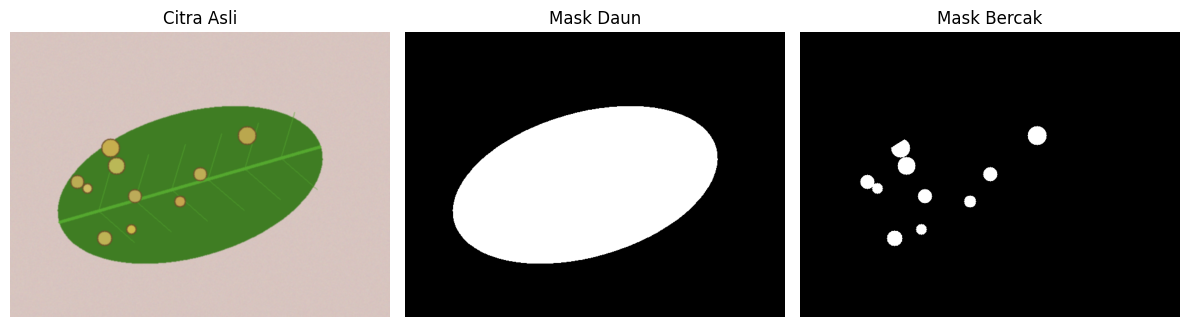

In [21]:
nama_citra = "teh_041.png"

path_citra = os.path.join(BERSIH, nama_citra)
path_mask_daun = os.path.join(MASK_DAUN, nama_citra)
path_mask_bercak = os.path.join(MASK_BERCAK, nama_citra)

img_bgr = cv2.imread(path_citra)

mask_daun = cv2.imread(path_mask_daun, cv2.IMREAD_GRAYSCALE)
mask_bercak = cv2.imread(path_mask_bercak, cv2.IMREAD_GRAYSCALE)

if img_bgr is None:
    raise FileNotFoundError(f"Citra tidak ditemukan: {path_citra}")

if mask_daun is None or mask_bercak is None:
    raise FileNotFoundError("Mask daun atau mask bercak tidak ditemukan.")

gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

print("Ukuran citra:", img_bgr.shape)
print("Ukuran grayscale:", gray.shape)

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB))
plt.title("Citra Asli")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(mask_daun, cmap="gray")
plt.title("Mask Daun")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(mask_bercak, cmap="gray")
plt.title("Mask Bercak")
plt.axis("off")

plt.tight_layout()
plt.show()

In [22]:
def konvolusi_manual(img, kernel):
    img = img.astype(np.float32)
    kernel = np.array(kernel, dtype=np.float32)

    tinggi, lebar = img.shape
    kh, kw = kernel.shape

    pad_h = kh // 2
    pad_w = kw // 2

    padded = np.pad(
        img,
        ((pad_h, pad_h), (pad_w, pad_w)),
        mode="edge"
    )

    hasil = np.zeros_like(img)

    for i in range(tinggi):
        for j in range(lebar):
            area = padded[i:i+kh, j:j+kw]
            hasil[i, j] = np.sum(area * kernel)

    return np.clip(hasil, 0, 255).astype(np.uint8)


def konvolusi_sejati(img, kernel):
    kernel_flip = np.flipud(np.fliplr(kernel))
    return konvolusi_manual(img, kernel_flip)


print("Fungsi konvolusi manual berhasil dibuat.")

Fungsi konvolusi manual berhasil dibuat.


Rata-rata selisih: 0.3526529947916667


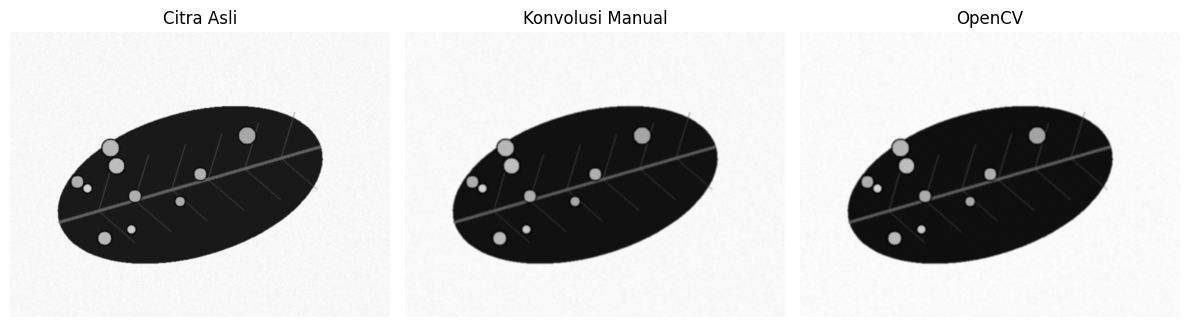

In [23]:
kernel_uji = np.ones((3, 3), dtype=np.float32) / 9

hasil_manual = konvolusi_manual(gray, kernel_uji)

hasil_opencv = cv2.filter2D(
    gray,
    -1,
    kernel_uji,
    borderType=cv2.BORDER_REPLICATE
)

selisih = np.mean(
    np.abs(
        hasil_manual.astype(float) -
        hasil_opencv.astype(float)
    )
)

print("Rata-rata selisih:", selisih)

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(gray, cmap="gray")
plt.title("Citra Asli")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(hasil_manual, cmap="gray")
plt.title("Konvolusi Manual")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(hasil_opencv, cmap="gray")
plt.title("OpenCV")
plt.axis("off")

plt.tight_layout()
plt.show()

In [24]:
def derau_gaussian(img, sigma, seed=SEED):
    random_generator = np.random.default_rng(seed)

    noise = random_generator.normal(
        0, sigma, img.shape
    )

    hasil = img.astype(np.float32) + noise

    return np.clip(hasil, 0, 255).astype(np.uint8)


def derau_salt_pepper(img, jumlah, seed=SEED):
    random_generator = np.random.default_rng(seed)

    hasil = img.copy()
    total = img.size
    banyak = int(total * jumlah)

    indeks = random_generator.choice(
        total, banyak, replace=False
    )

    setengah = banyak // 2

    flat = hasil.reshape(-1)
    flat[indeks[:setengah]] = 255
    flat[indeks[setengah:]] = 0

    return hasil


print("Fungsi penambahan derau berhasil dibuat.")

Fungsi penambahan derau berhasil dibuat.


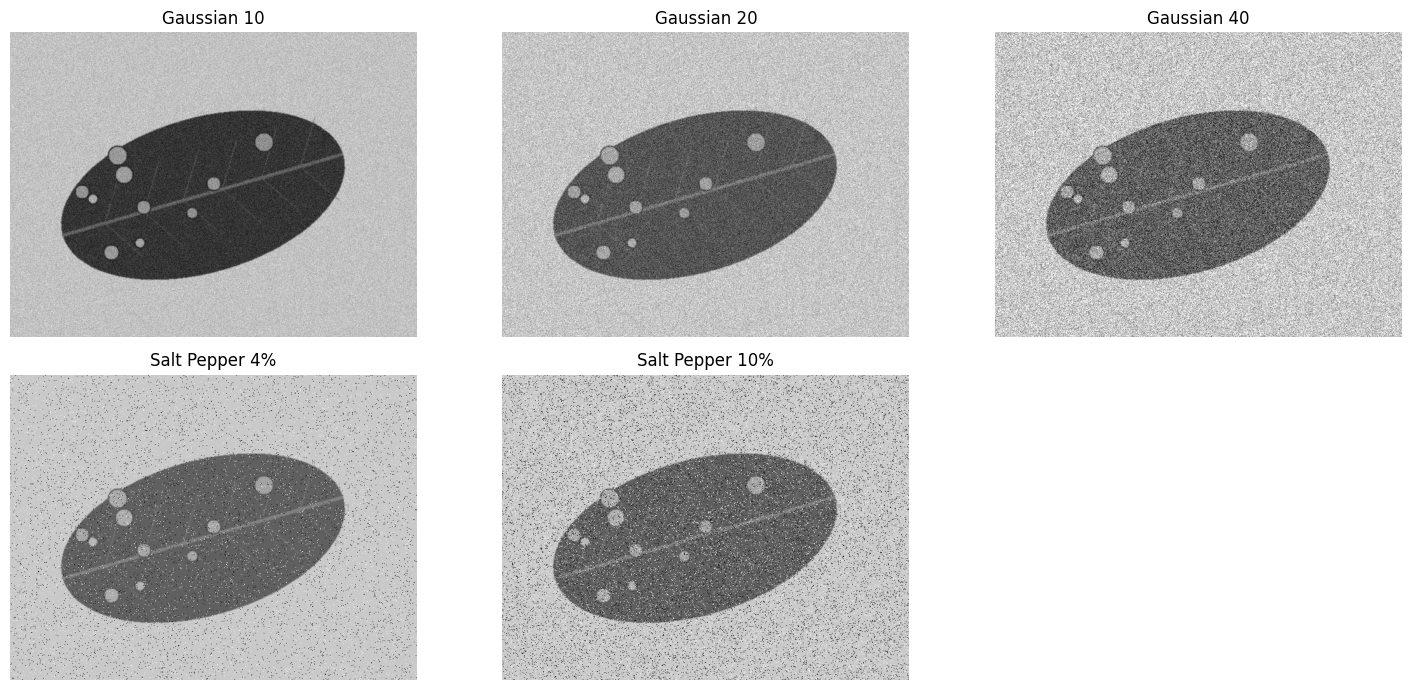

In [25]:
daftar_derau = {
    "Gaussian 10": derau_gaussian(gray, 10, SEED),
    "Gaussian 20": derau_gaussian(gray, 20, SEED),
    "Gaussian 40": derau_gaussian(gray, 40, SEED),
    "Salt Pepper 4%": derau_salt_pepper(gray, 0.04, SEED),
    "Salt Pepper 10%": derau_salt_pepper(gray, 0.10, SEED)
}

plt.figure(figsize=(15, 7))

for i, (nama, citra) in enumerate(daftar_derau.items()):
    plt.subplot(2, 3, i + 1)
    plt.imshow(citra, cmap="gray")
    plt.title(nama)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [26]:
def filter_mean(img, ukuran):
    kernel = np.ones((ukuran, ukuran), dtype=np.float32)
    kernel /= kernel.size

    return cv2.filter2D(
        img, -1, kernel,
        borderType=cv2.BORDER_REPLICATE
    )


def filter_gaussian(img):
    return cv2.GaussianBlur(
        img,
        (5, 5),
        0,
        borderType=cv2.BORDER_REPLICATE
    )


def filter_median(img, ukuran):
    return cv2.medianBlur(img, ukuran)


daftar_penapis = {
    "Mean 3x3": lambda x: filter_mean(x, 3),
    "Mean 5x5": lambda x: filter_mean(x, 5),
    "Gaussian 5x5": filter_gaussian,
    "Median 3x3": lambda x: filter_median(x, 3),
    "Median 5x5": lambda x: filter_median(x, 5),
    "Median 9x9": lambda x: filter_median(x, 9)
}

print("Jumlah penapis:", len(daftar_penapis))

Jumlah penapis: 6


In [27]:
def hitung_psnr(citra_asli, citra_hasil):
    asli = citra_asli.astype(np.float64)
    hasil = citra_hasil.astype(np.float64)

    mse = np.mean((asli - hasil) ** 2)

    if mse == 0:
        return float("inf")

    return 10 * np.log10((255 ** 2) / mse)


def hitung_kb(kanal, mask_daun, mask_bercak):
    daun = mask_daun > 0
    bercak = mask_bercak > 0

    sehat = daun & (~bercak)
    area_bercak = daun & bercak

    nilai_sehat = kanal[sehat]
    nilai_bercak = kanal[area_bercak]

    if len(nilai_sehat) == 0 or len(nilai_bercak) == 0:
        return np.nan

    rata_sehat = np.mean(nilai_sehat)
    rata_bercak = np.mean(nilai_bercak)
    std_sehat = np.std(nilai_sehat)

    if std_sehat == 0:
        return np.nan

    return abs(rata_bercak - rata_sehat) / std_sehat


print("Fungsi PSNR dan KB berhasil dibuat.")

Fungsi PSNR dan KB berhasil dibuat.


In [28]:
hasil_pengujian = []

for nama_derau, citra_derau in daftar_derau.items():

    for nama_penapis, fungsi_penapis in daftar_penapis.items():

        waktu_awal = time.perf_counter()

        citra_hasil = fungsi_penapis(citra_derau)

        waktu_akhir = time.perf_counter()

        psnr = hitung_psnr(gray, citra_hasil)

        kb = hitung_kb(
            citra_hasil,
            mask_daun,
            mask_bercak
        )

        waktu = waktu_akhir - waktu_awal

        hasil_pengujian.append({
            "Derau": nama_derau,
            "Penapis": nama_penapis,
            "PSNR": psnr,
            "Waktu": waktu,
            "KB": kb
        })

df = pd.DataFrame(hasil_pengujian)

display(df.round(4))

path_csv = os.path.join(HASIL, "b4_tabel_penapis.csv")
df.to_csv(path_csv, index=False)

print("Tabel berhasil disimpan:", path_csv)

,Derau,Penapis,PSNR,Waktu,KB
0,Gaussian 10,Mean 3x3,36.7987,0.0024,6.7066
1,Gaussian 10,Mean 5x5,37.0917,0.0024,6.6939
2,Gaussian 10,Gaussian 5x5,37.7247,0.0007,6.8850
3,Gaussian 10,Median 3x3,35.5069,0.0022,6.7363
4,Gaussian 10,Median 5x5,38.4151,0.0011,7.6509
5,Gaussian 10,Median 9x9,38.5339,0.0602,8.2863
6,Gaussian 20,Mean 3x3,31.4329,0.0006,5.2584
7,Gaussian 20,Mean 5x5,34.2050,0.0018,6.0290
8,Gaussian 20,Gaussian 5x5,32.9013,0.0007,5.7248
9,Gaussian 20,Median 3x3,29.7556,0.0002,4.7603


Tabel berhasil disimpan: /content/drive/MyDrive/simuteh-1004/hasil/b4_tabel_penapis.csv


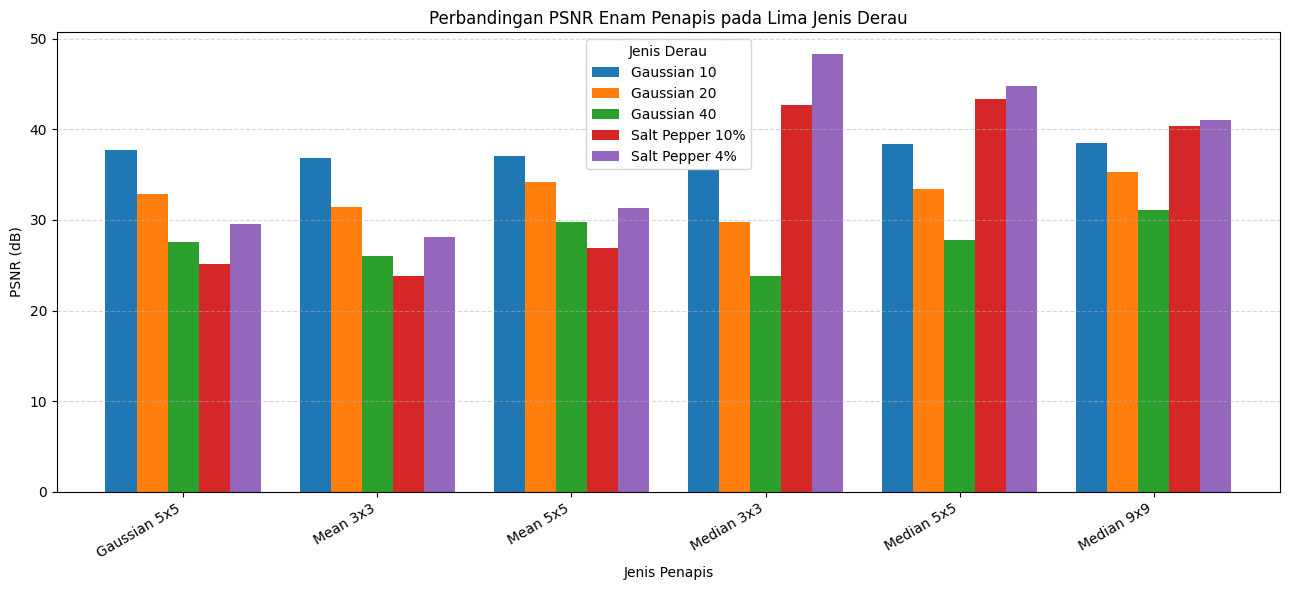

In [29]:
pivot_psnr = df.pivot(
    index="Penapis",
    columns="Derau",
    values="PSNR"
)

ax = pivot_psnr.plot(
    kind="bar",
    figsize=(13, 6),
    width=0.8
)

plt.title("Perbandingan PSNR Enam Penapis pada Lima Jenis Derau")
plt.xlabel("Jenis Penapis")
plt.ylabel("PSNR (dB)")
plt.xticks(rotation=30, ha="right")
plt.legend(title="Jenis Derau")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()

plt.savefig(
    os.path.join(HASIL, "b4_diagram_psnr.png"),
    dpi=300
)

plt.show()

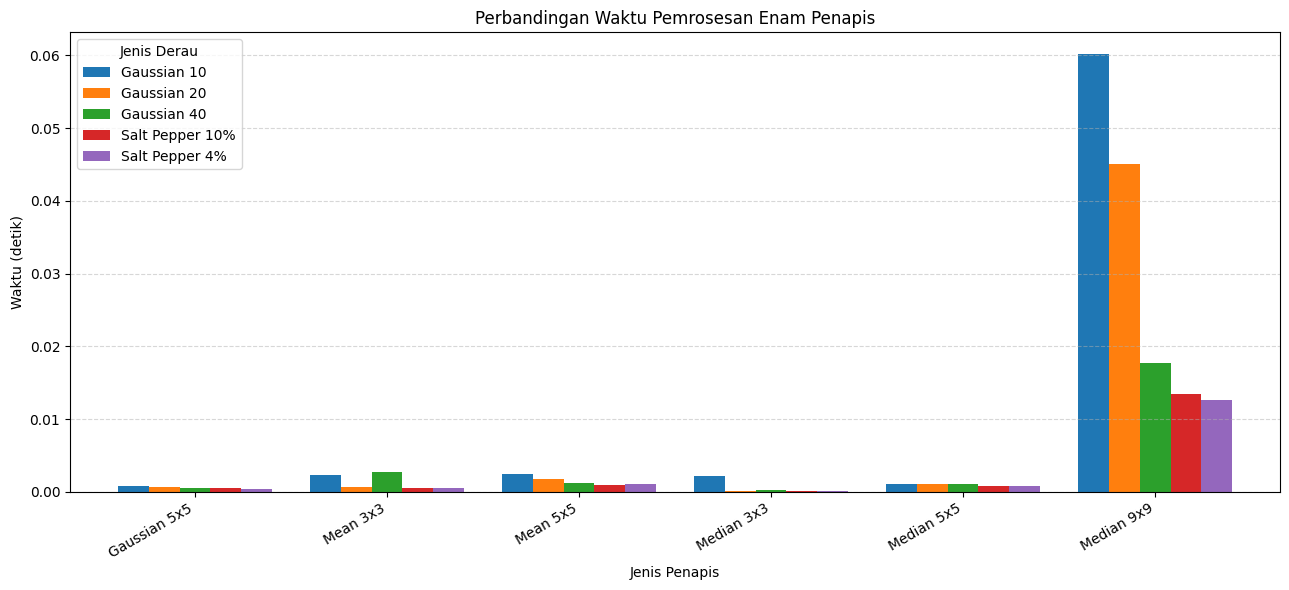

In [30]:
pivot_waktu = df.pivot(
    index="Penapis",
    columns="Derau",
    values="Waktu"
)

ax = pivot_waktu.plot(
    kind="bar",
    figsize=(13, 6),
    width=0.8
)

plt.title("Perbandingan Waktu Pemrosesan Enam Penapis")
plt.xlabel("Jenis Penapis")
plt.ylabel("Waktu (detik)")
plt.xticks(rotation=30, ha="right")
plt.legend(title="Jenis Derau")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()

plt.savefig(
    os.path.join(HASIL, "b4_diagram_waktu.png"),
    dpi=300
)

plt.show()

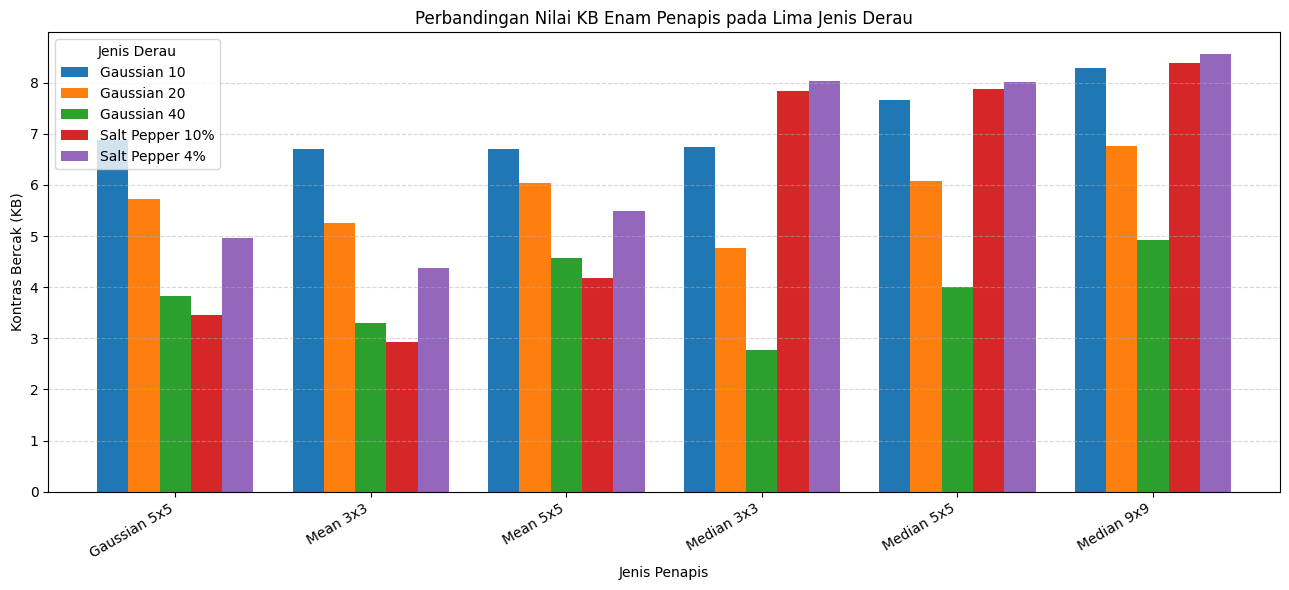

In [31]:
pivot_kb = df.pivot(
    index="Penapis",
    columns="Derau",
    values="KB"
)

ax = pivot_kb.plot(
    kind="bar",
    figsize=(13, 6),
    width=0.8
)

plt.title("Perbandingan Nilai KB Enam Penapis pada Lima Jenis Derau")
plt.xlabel("Jenis Penapis")
plt.ylabel("Kontras Bercak (KB)")
plt.xticks(rotation=30, ha="right")
plt.legend(title="Jenis Derau")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()

plt.savefig(
    os.path.join(HASIL, "b4_diagram_kb.png"),
    dpi=300
)

plt.show()

In [36]:
nama = "teh_021.png"

citra_asli = cv2.imread(
    os.path.join(BERSIH, nama)
)

mask_daun_021 = cv2.imread(
    os.path.join(MASK_DAUN, nama),
    cv2.IMREAD_GRAYSCALE
)

mask_bercak_021 = cv2.imread(
    os.path.join(MASK_BERCAK, nama),
    cv2.IMREAD_GRAYSCALE
)

if citra_asli is None:
    raise FileNotFoundError("Citra teh_021 tidak ditemukan.")

gray_021 = cv2.cvtColor(
    citra_asli,
    cv2.COLOR_BGR2GRAY
)

print("Ukuran citra:", gray_021.shape)
print("Jumlah piksel bercak:", np.count_nonzero(mask_bercak_021))

Ukuran citra: (480, 640)
Jumlah piksel bercak: 599


In [37]:
ukuran_filter = [3, 5, 9, 15]

hasil_median_021 = {}

for ukuran in ukuran_filter:
    hasil = cv2.medianBlur(gray_021, ukuran)
    hasil_median_021[ukuran] = hasil

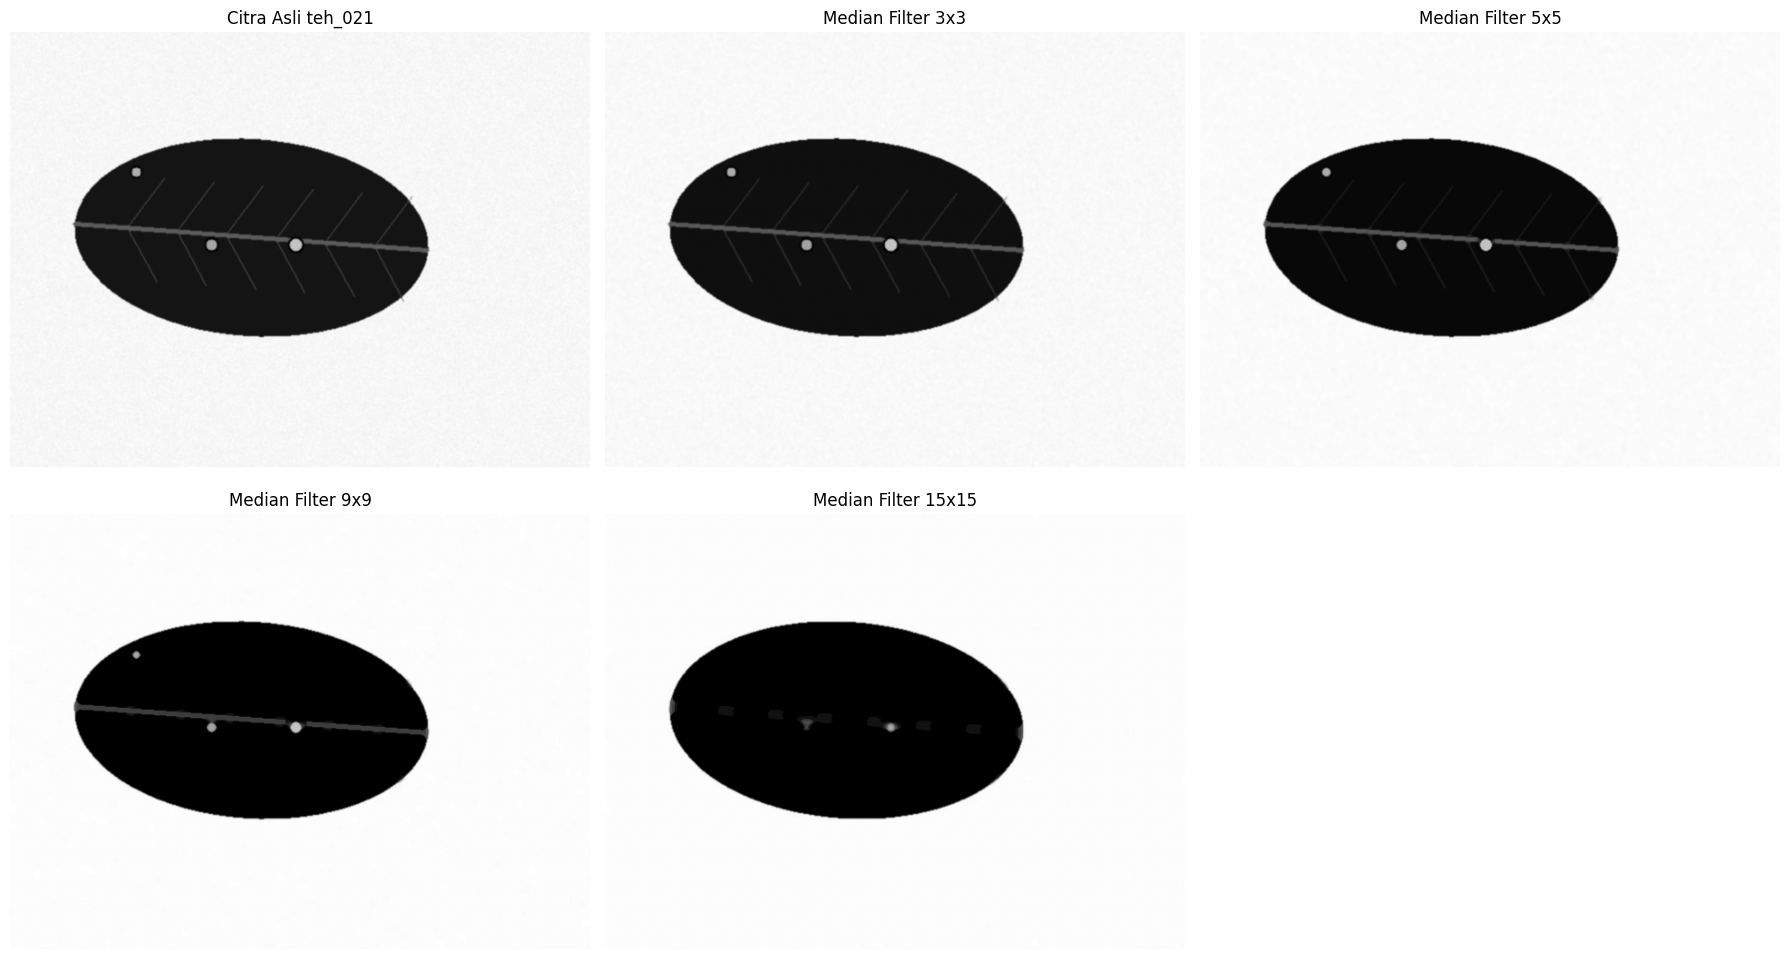

In [38]:
plt.figure(figsize=(18, 10))

plt.subplot(2, 3, 1)
plt.imshow(gray_021, cmap="gray")
plt.title("Citra Asli teh_021")
plt.axis("off")

for i, ukuran in enumerate(ukuran_filter):
    plt.subplot(2, 3, i + 2)
    plt.imshow(hasil_median_021[ukuran], cmap="gray")
    plt.title(f"Median Filter {ukuran}x{ukuran}")
    plt.axis("off")

plt.tight_layout()
plt.show()

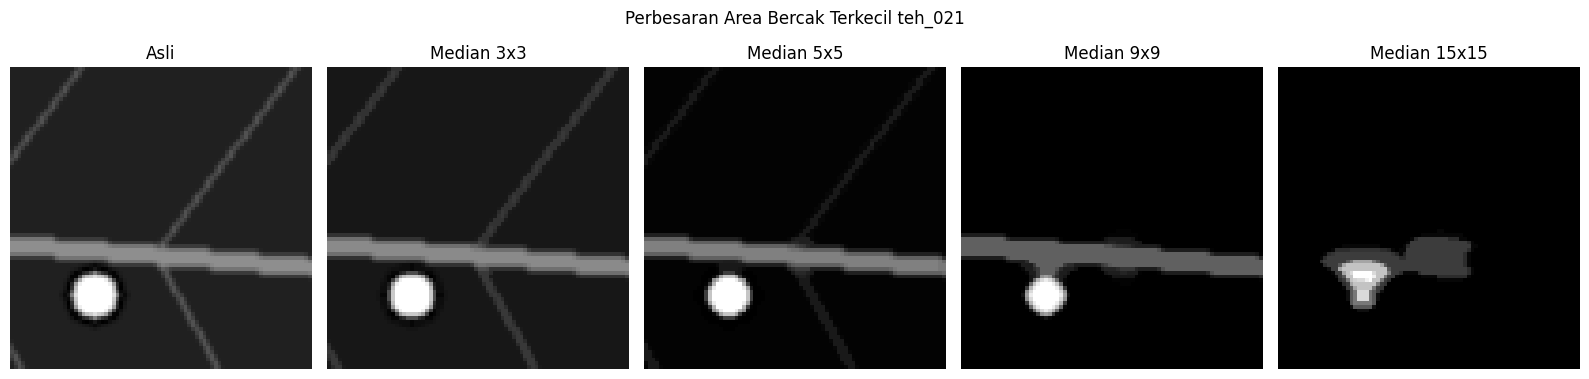

In [39]:
# Menentukan area bercak dari mask
y, x = np.where(mask_bercak_021 > 0)

if len(x) == 0:
    raise ValueError("Mask bercak teh_021 tidak memiliki piksel.")

# Menentukan titik tengah area bercak
cx = int(np.mean(x))
cy = int(np.mean(y))

# Ukuran area yang diperbesar
ukuran_crop = 80
setengah = ukuran_crop // 2

x1 = max(0, cx - setengah)
x2 = min(gray_021.shape[1], cx + setengah)
y1 = max(0, cy - setengah)
y2 = min(gray_021.shape[0], cy + setengah)

# Crop area bercak
crop_asli = gray_021[y1:y2, x1:x2]

plt.figure(figsize=(16, 4))

plt.subplot(1, 5, 1)
plt.imshow(crop_asli, cmap="gray")
plt.title("Asli")
plt.axis("off")

for i, ukuran in enumerate(ukuran_filter):
    crop_hasil = hasil_median_021[ukuran][y1:y2, x1:x2]

    plt.subplot(1, 5, i + 2)
    plt.imshow(crop_hasil, cmap="gray")
    plt.title(f"Median {ukuran}x{ukuran}")
    plt.axis("off")

plt.suptitle("Perbesaran Area Bercak Terkecil teh_021")
plt.tight_layout()
plt.show()

In [32]:
ukuran_median = [1, 3, 5, 9, 15]

hasil_median = []

citra_uji = daftar_derau["Salt Pepper 10%"]

for ukuran in ukuran_median:

    waktu_awal = time.perf_counter()

    if ukuran == 1:
        hasil = citra_uji.copy()
    else:
        hasil = cv2.medianBlur(citra_uji, ukuran)

    waktu_akhir = time.perf_counter()

    psnr = hitung_psnr(gray, hasil)

    hasil_median.append({
        "Ukuran": ukuran,
        "PSNR": psnr,
        "Waktu": waktu_akhir - waktu_awal
    })

df_median = pd.DataFrame(hasil_median)

display(df_median.round(4))

df_median.to_csv(
    os.path.join(HASIL, "b4_pengujian_ukuran_median.csv"),
    index=False
)

,Ukuran,PSNR,Waktu
0,1,15.0241,0.0004
1,3,42.6575,0.0002
2,5,43.3747,0.0010
3,9,40.4197,0.0125
4,15,35.5892,0.0184


In [40]:
folder_b4 = os.path.join(HASIL, "bercak_terkecil_teh_021")
os.makedirs(folder_b4, exist_ok=True)

cv2.imwrite(
    os.path.join(folder_b4, "teh_021_asli.png"),
    gray_021
)

for ukuran, hasil in hasil_median_021.items():
    cv2.imwrite(
        os.path.join(
            folder_b4,
            f"teh_021_median_{ukuran}.png"
        ),
        hasil
    )

print("Hasil pengujian tersimpan di:", folder_b4)

Hasil pengujian tersimpan di: /content/drive/MyDrive/simuteh-1004/hasil/bercak_terkecil_teh_021


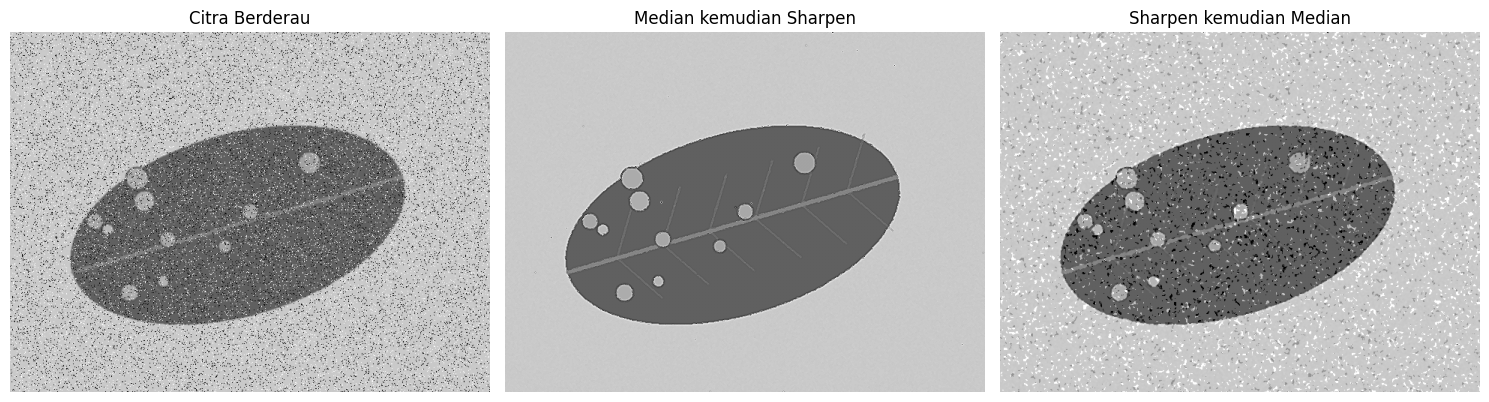

PSNR Median-Sharpen: 32.25641156008904
PSNR Sharpen-Median: 21.72497296832367


In [33]:
kernel_sharpen = np.array([
    [0, -1, 0],
    [-1, 5, -1],
    [0, -1, 0]
], dtype=np.float32)

citra_derau = daftar_derau["Salt Pepper 10%"]

# Median kemudian sharpen
median_dahulu = cv2.medianBlur(citra_derau, 3)
hasil_median_sharpen = cv2.filter2D(
    median_dahulu,
    -1,
    kernel_sharpen
)

# Sharpen kemudian median
sharpen_dahulu = cv2.filter2D(
    citra_derau,
    -1,
    kernel_sharpen
)
hasil_sharpen_median = cv2.medianBlur(
    sharpen_dahulu,
    3
)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(citra_derau, cmap="gray")
plt.title("Citra Berderau")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(hasil_median_sharpen, cmap="gray")
plt.title("Median kemudian Sharpen")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(hasil_sharpen_median, cmap="gray")
plt.title("Sharpen kemudian Median")
plt.axis("off")

plt.tight_layout()
plt.show()

print(
    "PSNR Median-Sharpen:",
    hitung_psnr(gray, hasil_median_sharpen)
)

print(
    "PSNR Sharpen-Median:",
    hitung_psnr(gray, hasil_sharpen_median)
)

In [34]:
daftar_citra_uji = [
    f"teh_{i:03d}.png"
    for i in range(1, 57, 5)
]

hasil_multi = []

for nama in daftar_citra_uji:

    path = os.path.join(BERSIH, nama)
    citra = cv2.imread(path)

    if citra is None:
        print("Citra dilewati:", nama)
        continue

    citra_gray = cv2.cvtColor(
        citra,
        cv2.COLOR_BGR2GRAY
    )

    citra_derau = derau_salt_pepper(
        citra_gray,
        0.10,
        SEED
    )

    hasil_filter = cv2.medianBlur(
        citra_derau,
        3
    )

    psnr_sebelum = hitung_psnr(
        citra_gray,
        citra_derau
    )

    psnr_sesudah = hitung_psnr(
        citra_gray,
        hasil_filter
    )

    hasil_multi.append({
        "Citra": nama,
        "PSNR Sebelum": psnr_sebelum,
        "PSNR Sesudah": psnr_sesudah
    })

df_multi = pd.DataFrame(hasil_multi)

display(df_multi.round(4))

df_multi.to_csv(
    os.path.join(HASIL, "b4_pengujian_multi_citra.csv"),
    index=False
)

,Citra,PSNR Sebelum,PSNR Sesudah
0,teh_001.png,15.3998,43.7629
1,teh_006.png,15.0833,43.5831
2,teh_011.png,14.9419,42.8589
3,teh_016.png,15.1550,43.5239
4,teh_021.png,14.8647,42.9582
5,teh_026.png,15.1784,43.3817
6,teh_031.png,15.1575,42.9810
7,teh_036.png,15.1832,43.3362
8,teh_041.png,15.0241,42.6575
9,teh_046.png,15.2035,42.7810


In [35]:
print("=== HASIL PENGUJIAN B4 ===")

print("\nJumlah kombinasi pengujian:")
print(len(df))

print("\nRata-rata PSNR:")
print(df.groupby("Penapis")["PSNR"].mean().round(4))

print("\nRata-rata waktu pemrosesan:")
print(df.groupby("Penapis")["Waktu"].mean().round(6))

print("\nRata-rata KB:")
print(df.groupby("Penapis")["KB"].mean().round(4))

print("\nFile hasil tersimpan di:")
print(HASIL)

print("\nDaftar file:")
for file in sorted(os.listdir(HASIL)):
    if file.startswith("b4_"):
        print("-", file)

=== HASIL PENGUJIAN B4 ===

Jumlah kombinasi pengujian:
30

Rata-rata PSNR:
Penapis
Gaussian 5x5    30.5961
Mean 3x3        29.2306
Mean 5x5        31.8374
Median 3x3      36.0132
Median 5x5      37.5692
Median 9x9      37.2701
Name: PSNR, dtype: float64

Rata-rata waktu pemrosesan:
Penapis
Gaussian 5x5    0.000561
Mean 3x3        0.001308
Mean 5x5        0.001484
Median 3x3      0.000556
Median 5x5      0.000955
Median 9x9      0.029816
Name: Waktu, dtype: float64

Rata-rata KB:
Penapis
Gaussian 5x5    4.9698
Mean 3x3        4.5146
Mean 5x5        5.3913
Median 3x3      6.0260
Median 5x5      6.7236
Median 9x9      7.3835
Name: KB, dtype: float64

File hasil tersimpan di:
/content/drive/MyDrive/simuteh-1004/hasil

Daftar file:
- b4_crop_bercak.png
- b4_diagram_kb.png
- b4_diagram_psnr.png
- b4_diagram_waktu.png
- b4_grafik_di_kernel.png
- b4_grafik_psnr.png
- b4_grafik_waktu.png
- b4_lima_jenis_derau.png
- b4_pengaruh_kernel_median.csv
- b4_pengujian_multi_citra.csv
- b4_pengujian_uku